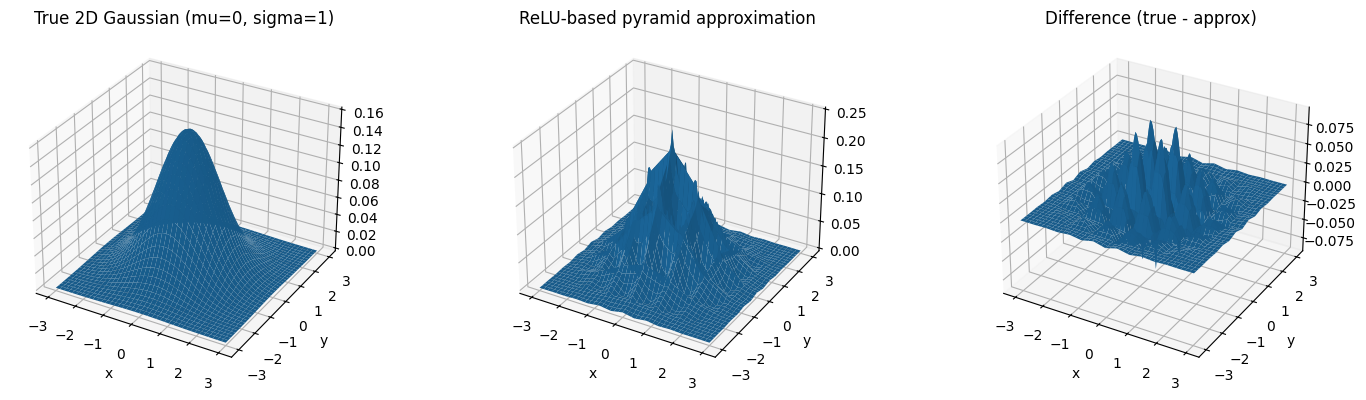

RMS error of approximation on grid: 1.356996e-02


In [5]:
# Exercise-1
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def true_gaussian(X, Y, mu=0.0, sigma=1.0):
    Z = (1.0/(2*np.pi*sigma**2)) * np.exp(-((X-mu)**2 + (Y-mu)**2)/(2*sigma**2))
    return Z

def ReLU(X, Y, cx, cy, r):
    return np.maximum(0.0, r - (np.abs(X-cx) + np.abs(Y-cy)))

def ReLU_approx(X, Y, centers, r, weights):
    Z = np.zeros_like(X)
    for (cx,cy), w in zip(centers, weights):
        Z += w * ReLU(X,Y,cx,cy,r)
    return Z

grid = np.linspace(-3,3,121)
X, Y = np.meshgrid(grid, grid)

Z_true = true_gaussian(X,Y,mu=0.0,sigma=1.0)

centers = []
nx = ny = 7  
coords = np.linspace(-2.5, 2.5, nx)
for cx in coords:
    for cy in coords:
        centers.append((cx, cy))

r = 0.9  
weights = [true_gaussian(np.array([[cx]]), np.array([[cy]]), mu=0.0, sigma=1.0)[0,0] for (cx,cy) in centers]

Z_approx = ReLU_approx(X, Y, centers, r, weights)

scale = Z_true.sum() / (Z_approx.sum() + 1e-12)
Z_approx *= scale

fig = plt.figure(figsize=(15,4))

ax = fig.add_subplot(1,3,1, projection='3d')
ax.plot_surface(X, Y, Z_true, rstride=3, cstride=3, linewidth=0, antialiased=True)
ax.set_title('True 2D Gaussian (mu=0, sigma=1)')
ax.set_xlabel('x'); ax.set_ylabel('y')

ax = fig.add_subplot(1,3,2, projection='3d')
ax.plot_surface(X, Y, Z_approx, rstride=3, cstride=3, linewidth=0, antialiased=True)
ax.set_title('ReLU-based pyramid approximation')
ax.set_xlabel('x'); ax.set_ylabel('y')

ax = fig.add_subplot(1,3,3, projection='3d')
ax.plot_surface(X, Y, Z_true - Z_approx, rstride=3, cstride=3, linewidth=0, antialiased=True)
ax.set_title('Difference (true - approx)')
ax.set_xlabel('x'); ax.set_ylabel('y')

plt.tight_layout()
plt.show()

rms = np.sqrt(np.mean((Z_true - Z_approx)**2))
print(f'RMS error of approximation on grid: {rms:.6e}')

In [6]:
# Exercise-2
import sympy as sp

n, m = sp.symbols('n m', integer=True, positive=True)
d = sp.symbols('d', integer=True, positive=True)
k = sp.symbols('k1:'+str(1+4)) 

explanation = '''
Let k_0 = n, k_{d+1} = m, and for l=1..d let k_l be sizes of hidden layers.
The number of weight parameters between layer l-1 and l is k_{l-1} * k_l which are the connection weights.
Each neuron in layer l has a bias, so we add k_l biases.
Total parameters (weights + biases) = sum_{l=1}^{d+1} (k_{l-1} * k_l + k_l)
= sum_{l=1}^{d+1} k_{l-1} * k_l + sum_{l=1}^{d+1} k_l.
Here k_0 = n and k_{d+1} = m.
'''
print(explanation)

def total_params(layer_sizes):
    total = 0
    for i in range(1, len(layer_sizes)):
        total += layer_sizes[i-1] * layer_sizes[i]  
        total += layer_sizes[i] 
    return total

example = total_params([5,10,8,3])
print('Example (n=5, k1=10, k2=8, m=3) total parameters (weights+biases):', example)


Let k_0 = n, k_{d+1} = m, and for l=1..d let k_l be sizes of hidden layers.
The number of weight parameters between layer l-1 and l is k_{l-1} * k_l which are the connection weights.
Each neuron in layer l has a bias, so we add k_l biases.
Total parameters (weights + biases) = sum_{l=1}^{d+1} (k_{l-1} * k_l + k_l)
= sum_{l=1}^{d+1} k_{l-1} * k_l + sum_{l=1}^{d+1} k_l.
Here k_0 = n and k_{d+1} = m.

Example (n=5, k1=10, k2=8, m=3) total parameters (weights+biases): 175
